# SoH Span Deep Investigation

## Imports & Config

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import defaultdict

work_dir = os.getcwd()
PROC_DIR = os.path.join(work_dir, "data_processed")

# Column layout of processed files: [time, voltage, current, temperature, SoH]
SOH_COL = -1
TIME_COL = 0
CURRENT_COL = 2
MIN_SPAN_PCT = 5.0
ACTIVE_I_THRESH = 0.05


def get_battery_id(fname):
    parts = fname.split("_")
    for p in parts:
        if p.startswith("P") and p[1:].isdigit():
            return p
    return parts[1] if len(parts) > 1 else fname


proc_files = sorted([f for f in os.listdir(PROC_DIR) if f.endswith(".npy")])
battery_files = defaultdict(list)
for f in proc_files:
    battery_files[get_battery_id(f)].append(f)
batteries = sorted(battery_files.keys())
print(f"Processed files : {len(proc_files)}")
print(f"Batteries       : {len(batteries)}")


Processed files : 228
Batteries       : 76


# Section 1: Where Does the Span Come From?
Separates within-file span from across-file span.

In [ ]:
results = []
for bid in batteries:
    files = battery_files[bid]
    file_spans, file_lengths, file_soh_means, all_soh = [], [], [], []
    for f in files:
        x = np.load(os.path.join(PROC_DIR, f))
        soh = x[:, SOH_COL]
        file_spans.append(soh.max() - soh.min())
        file_lengths.append(len(x))
        file_soh_means.append(soh.mean())
        all_soh.append(soh)
    cat = np.concatenate(all_soh)
    battery_span = cat.max() - cat.min()
    within_span = np.mean(file_spans)
    across_span = max(file_soh_means) - min(file_soh_means)
    results.append(
        {
            "battery": bid,
            "n_files": len(files),
            "battery_span": battery_span,
            "within_span": within_span,
            "across_span": across_span,
            "soh_min": cat.min(),
            "soh_max": cat.max(),
            "soh_mean": cat.mean(),
            "total_len": sum(file_lengths),
            "file_spans": file_spans,
            "file_soh_means": file_soh_means,
        }
    )

battery_spans = np.array([r["battery_span"] for r in results])
within_spans = np.array([r["within_span"] for r in results])
across_spans = np.array([r["across_span"] for r in results])
n_informative = int((battery_spans >= MIN_SPAN_PCT).sum())

print(f"Battery-level span (global max-min):")
print(
    f"  min={battery_spans.min():.2f}%  median={np.median(battery_spans):.2f}%  "
    f"max={battery_spans.max():.2f}%"
)
print(f"Within-file span avg : {within_spans.mean():.2f}%")
print(f"Across-file span avg : {across_spans.mean():.2f}%")
print(f"Informative (≥{MIN_SPAN_PCT}%): {n_informative}/{len(batteries)}")


Battery-level span (global max-min):
  min=16.36%  median=29.67%  max=29.81%
Within-file span avg : 27.77%
Across-file span avg : 0.95%
Informative (≥5.0%): 76/76


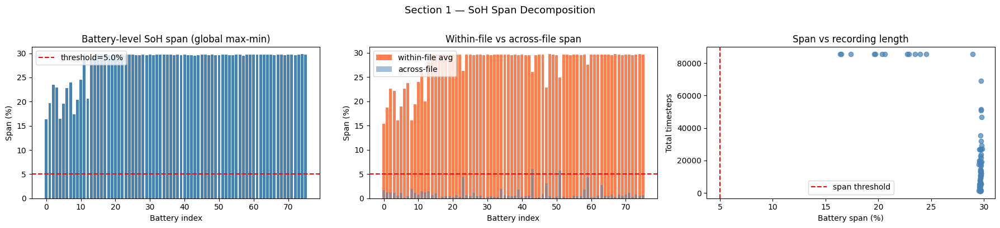

────────────────────────────────────────────────────────────
KEY: Most span is WITHIN individual files.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
bids = [r["battery"] for r in results]
axes[0].bar(range(len(bids)), battery_spans, color="steelblue")
axes[0].axhline(MIN_SPAN_PCT, color="red", ls="--", label=f"threshold={MIN_SPAN_PCT}%")
axes[0].set_title("Battery-level SoH span (global max-min)")
axes[0].set_xlabel("Battery index")
axes[0].set_ylabel("Span (%)")
axes[0].legend()

axes[1].bar(range(len(bids)), within_spans, color="coral", label="within-file avg")
axes[1].bar(
    range(len(bids)), across_spans, color="steelblue", alpha=0.5, label="across-file"
)
axes[1].axhline(MIN_SPAN_PCT, color="red", ls="--")
axes[1].set_title("Within-file vs across-file span")
axes[1].set_xlabel("Battery index")
axes[1].set_ylabel("Span (%)")
axes[1].legend()

axes[2].scatter(
    battery_spans, [r["total_len"] for r in results], c="steelblue", alpha=0.7
)
axes[2].axvline(MIN_SPAN_PCT, color="red", ls="--", label="span threshold")
axes[2].set_title("Span vs recording length")
axes[2].set_xlabel("Battery span (%)")
axes[2].set_ylabel("Total timesteps")
axes[2].legend()

plt.suptitle("Section 1 — SoH Span Decomposition", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print("─" * 60)
dom = (
    "WITHIN individual files"
    if within_spans.mean() > across_spans.mean()
    else "ACROSS files of the same battery"
)
print(f"Most span is {dom}.")


# Section 2: Full SoH Trajectory per Battery

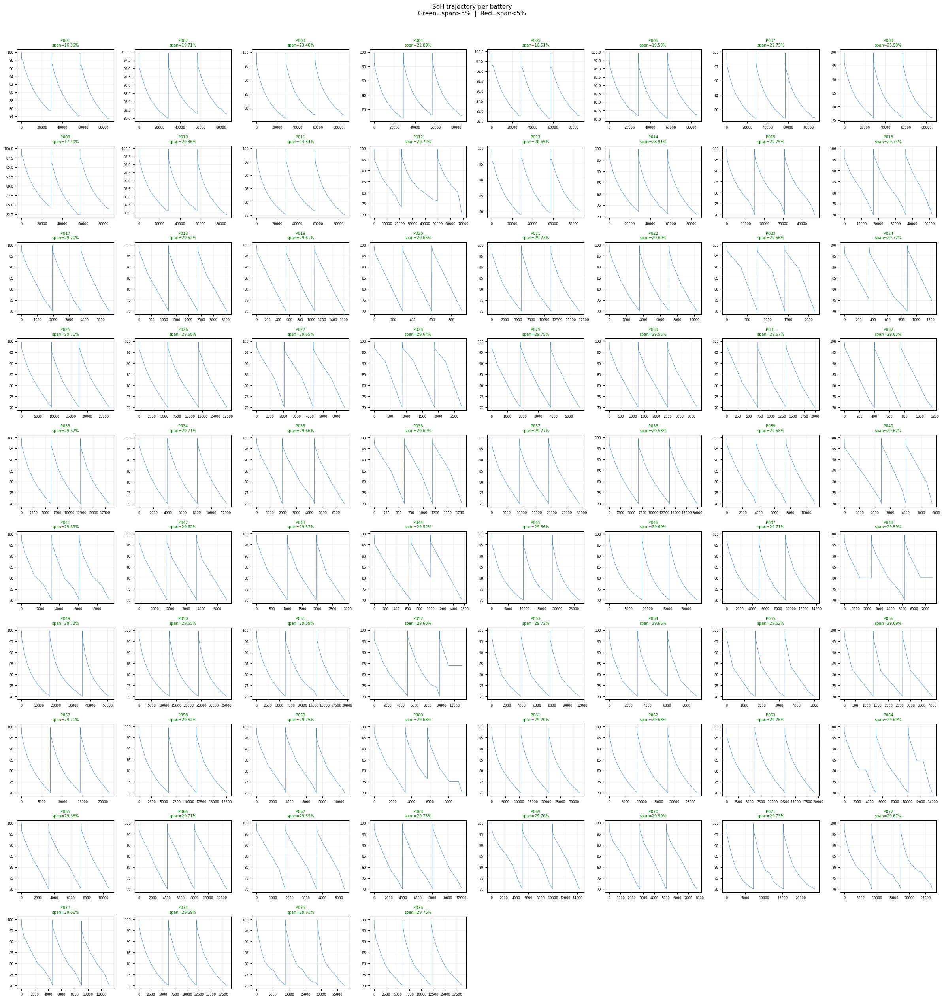

In [ ]:
n_bats = len(batteries)
ncols = 8
nrows = int(np.ceil(n_bats / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3, nrows * 2.5))
axes = axes.flatten()

for i, r in enumerate(results):
    ax = axes[i]
    bid = r["battery"]
    soh = np.concatenate(
        [
            np.load(os.path.join(PROC_DIR, f))[:, SOH_COL]
            for f in sorted(battery_files[bid])
        ]
    )
    ax.plot(soh, lw=0.6, color="steelblue")
    span = soh.max() - soh.min()
    color = "green" if span >= MIN_SPAN_PCT else "red"
    ax.set_title(f"{bid}\nspan={span:.2f}%", fontsize=7, color=color)
    ax.tick_params(labelsize=6)
    ax.grid(alpha=0.2)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    "SoH trajectory per battery\nGreen=span≥5%  |  Red=span<5%", fontsize=11, y=1.01
)
plt.tight_layout()
plt.show()


# Section 3: File-Level SoH Statistics Table

In [ ]:
print(
    f"{'Battery':<10} {'Files':>6} {'SoH_min':>9} {'SoH_max':>9} {'Span':>8}  File_means (sorted)"
)
print("-" * 80)
for r in results:
    means_str = "  ".join(f"{m:.2f}" for m in sorted(r["file_soh_means"]))
    flag = "✅" if r["battery_span"] >= MIN_SPAN_PCT else "❌"
    print(
        f"{r['battery']:<10} {r['n_files']:>6} {r['soh_min']:>9.2f} "
        f"{r['soh_max']:>9.2f} {r['battery_span']:>7.2f}%   [{means_str}] {flag}"
    )


Battery     Files   SoH_min   SoH_max     Span  File_means (sorted)
--------------------------------------------------------------------------------
P001            3     83.45     99.81   16.36%   [88.55  89.06  90.25] ✅
P002            3     79.95     99.66   19.71%   [85.33  86.54  86.59] ✅
P003            3     76.26     99.71   23.46%   [82.59  83.74  83.77] ✅
P004            3     76.84     99.73   22.89%   [83.05  83.96  84.13] ✅
P005            3     83.11     99.62   16.51%   [88.09  88.61  88.66] ✅
P006            3     80.13     99.72   19.59%   [85.67  86.30  86.80] ✅
P007            3     76.90     99.66   22.75%   [83.21  83.26  83.26] ✅
P008            3     75.65     99.63   23.98%   [82.42  82.59  82.85] ✅
P009            3     82.39     99.80   17.40%   [87.59  88.93  89.55] ✅
P010            3     79.40     99.76   20.36%   [85.13  86.23  86.24] ✅
P011            3     75.17     99.71   24.54%   [82.15  82.24  82.97] ✅
P012            3     70.00     99.72   29.72%  

# Section 4: Active vs Rest Analysis

Active fraction: min=0.027  median=0.743  max=0.901
Est. cycles    : min=157  median=1004  max=5692


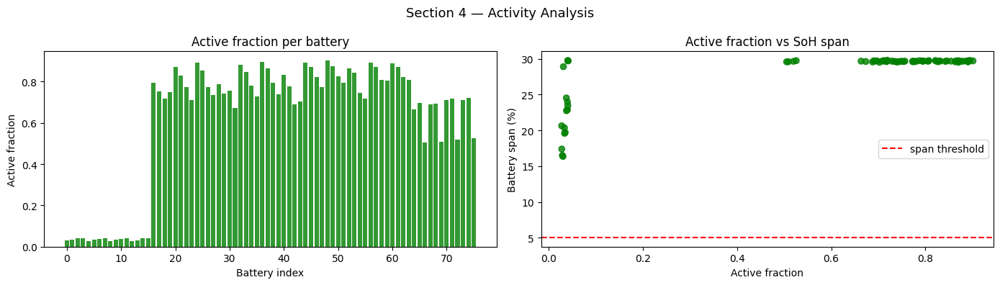

In [ ]:
active_fracs, cycle_counts = [], []
for r in results:
    current = np.concatenate(
        [
            np.load(os.path.join(PROC_DIR, f))[:, CURRENT_COL]
            for f in battery_files[r["battery"]]
        ]
    )
    mask = np.abs(current) > ACTIVE_I_THRESH
    sign = np.sign(current[mask]) if mask.sum() > 0 else np.array([])
    trans = int(np.sum(np.diff(sign) != 0)) if len(sign) > 1 else 0
    active_fracs.append(mask.mean())
    cycle_counts.append(trans // 2)

active_fracs = np.array(active_fracs)
cycle_counts = np.array(cycle_counts)
print(
    f"Active fraction: min={active_fracs.min():.3f}  median={np.median(active_fracs):.3f}  max={active_fracs.max():.3f}"
)
print(
    f"Est. cycles    : min={cycle_counts.min()}  median={np.median(cycle_counts):.0f}  max={cycle_counts.max()}"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
c = ["green" if s >= MIN_SPAN_PCT else "red" for s in battery_spans]
axes[0].bar(range(len(batteries)), active_fracs, color=c, alpha=0.8)
axes[0].set_title("Active fraction per battery")
axes[0].set_xlabel("Battery index")
axes[0].set_ylabel("Active fraction")
axes[1].scatter(active_fracs, battery_spans, c=c, alpha=0.8)
axes[1].axhline(MIN_SPAN_PCT, color="red", ls="--", label="span threshold")
axes[1].set_title("Active fraction vs SoH span")
axes[1].set_xlabel("Active fraction")
axes[1].set_ylabel("Battery span (%)")
axes[1].legend()
plt.suptitle("Section 4 — Activity Analysis", fontsize=13)
plt.tight_layout()
plt.show()


# Section 5: Informative Batteries Deep Dive

Informative batteries (span >= 5.0%): 76
  P001  span=16.36%  SoH=[83.45,99.81]  files=3
  P002  span=19.71%  SoH=[79.95,99.66]  files=3
  P003  span=23.46%  SoH=[76.26,99.71]  files=3
  P004  span=22.89%  SoH=[76.84,99.73]  files=3
  P005  span=16.51%  SoH=[83.11,99.62]  files=3
  P006  span=19.59%  SoH=[80.13,99.72]  files=3
  P007  span=22.75%  SoH=[76.90,99.66]  files=3
  P008  span=23.98%  SoH=[75.65,99.63]  files=3
  P009  span=17.40%  SoH=[82.39,99.80]  files=3
  P010  span=20.36%  SoH=[79.40,99.76]  files=3
  P011  span=24.54%  SoH=[75.17,99.71]  files=3
  P012  span=29.72%  SoH=[70.00,99.72]  files=3
  P013  span=20.65%  SoH=[79.00,99.64]  files=3
  P014  span=28.91%  SoH=[70.85,99.76]  files=3
  P015  span=29.75%  SoH=[70.00,99.76]  files=3
  P016  span=29.74%  SoH=[70.00,99.74]  files=3
  P017  span=29.70%  SoH=[70.00,99.70]  files=3
  P018  span=29.62%  SoH=[70.00,99.62]  files=3
  P019  span=29.61%  SoH=[70.00,99.61]  files=3
  P020  span=29.66%  SoH=[70.00,99.66]  files=3

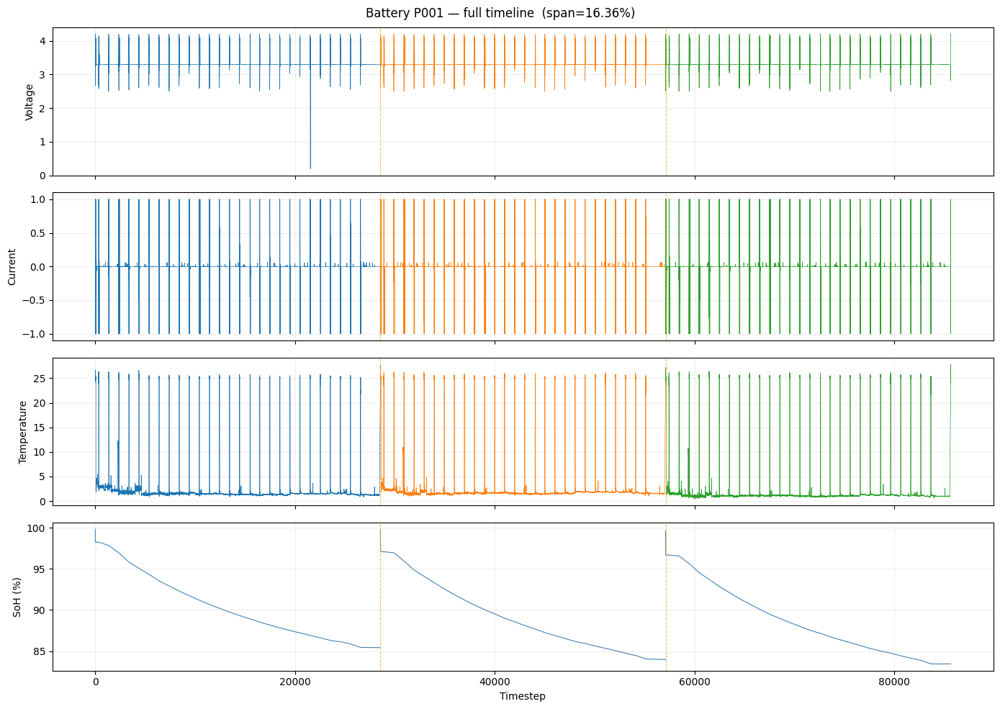

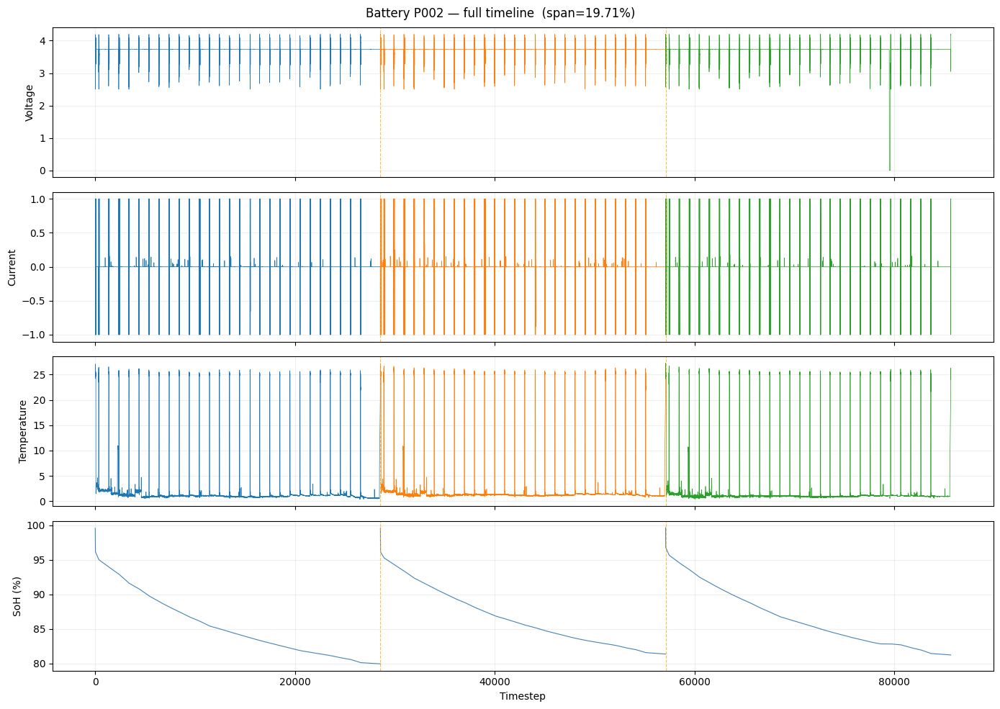

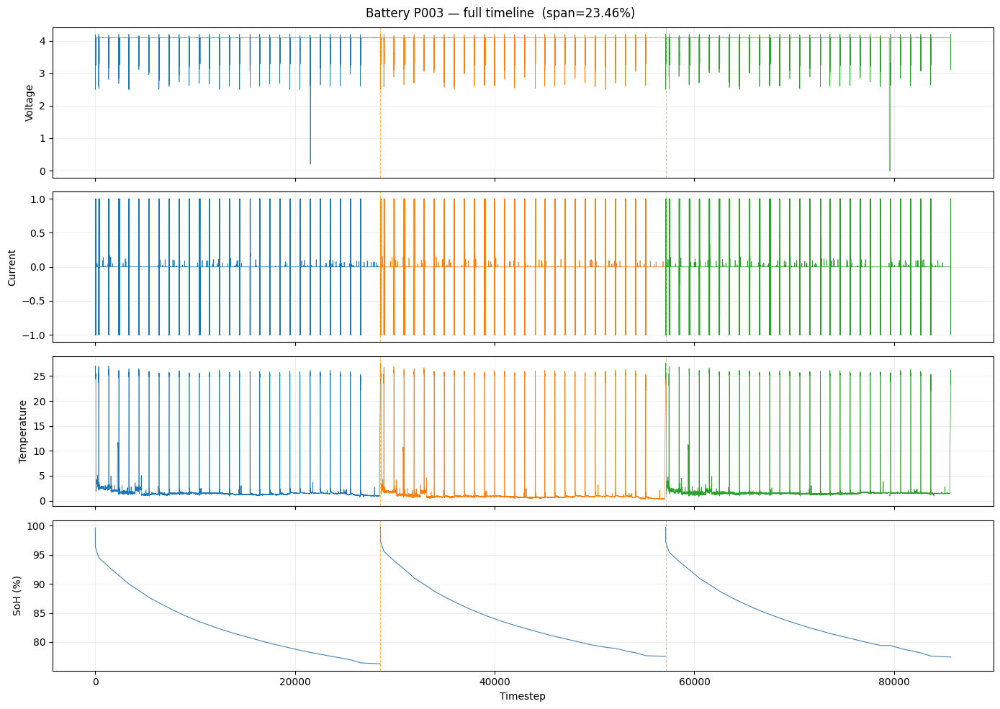

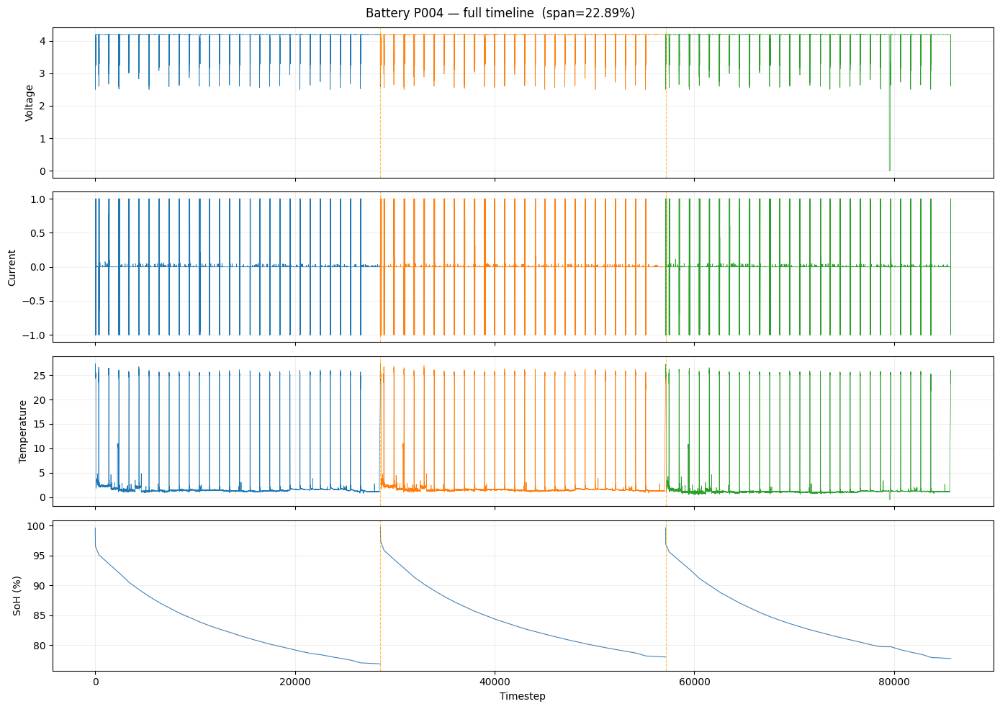

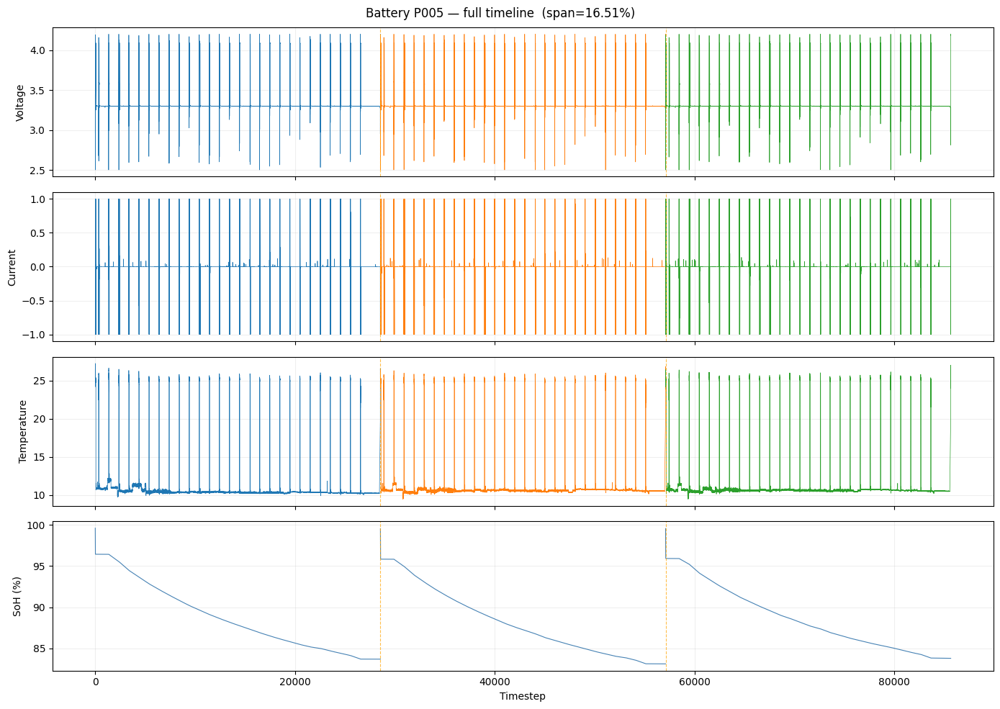

...

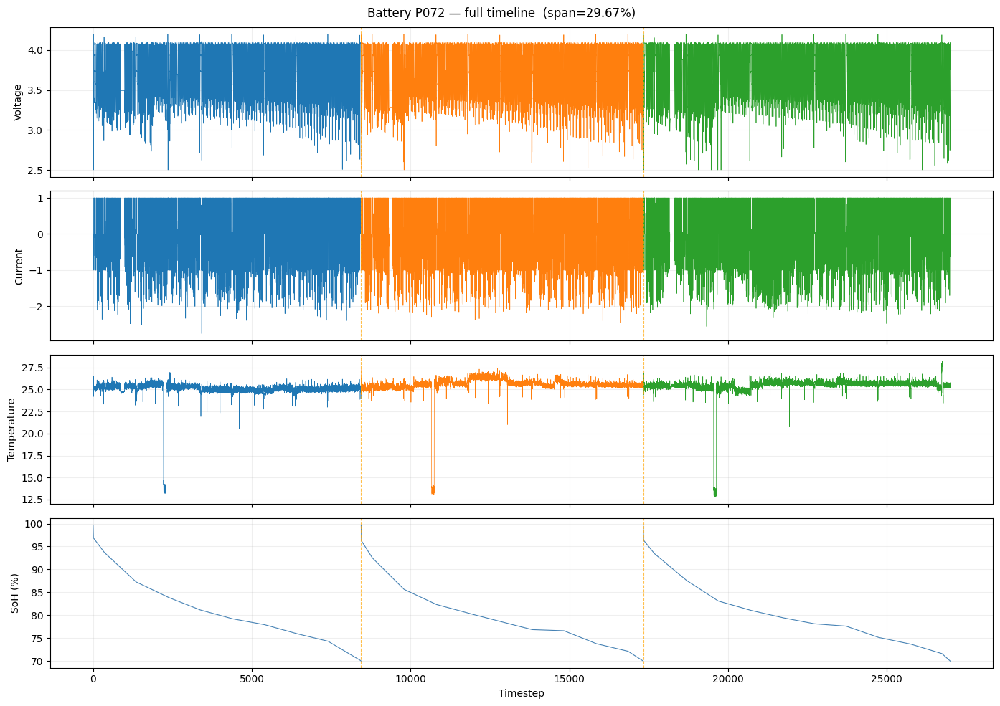

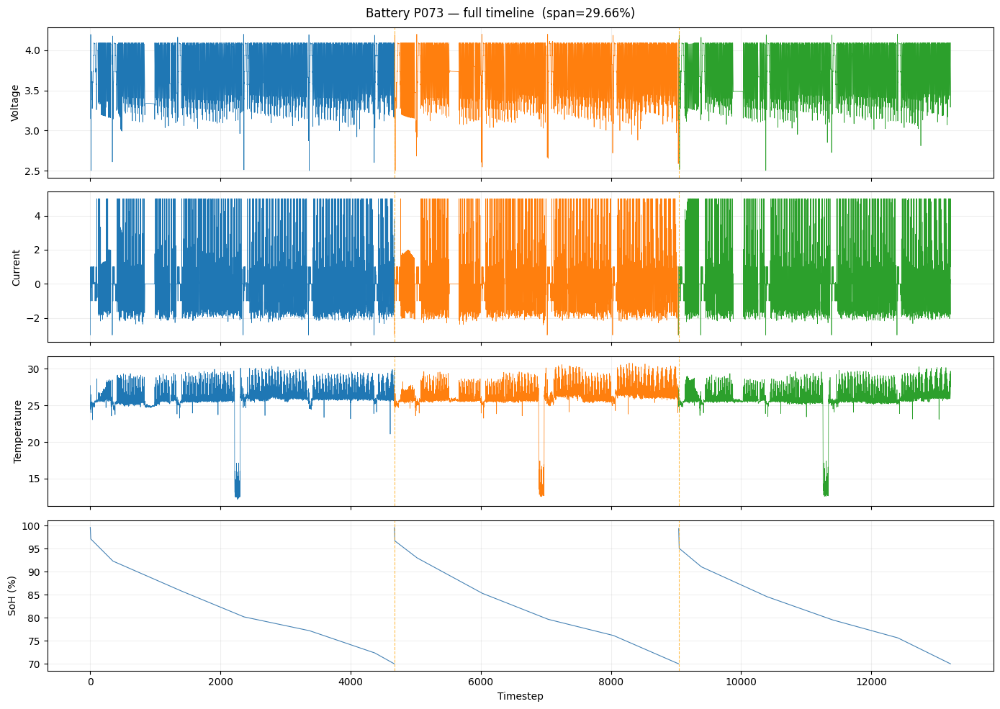

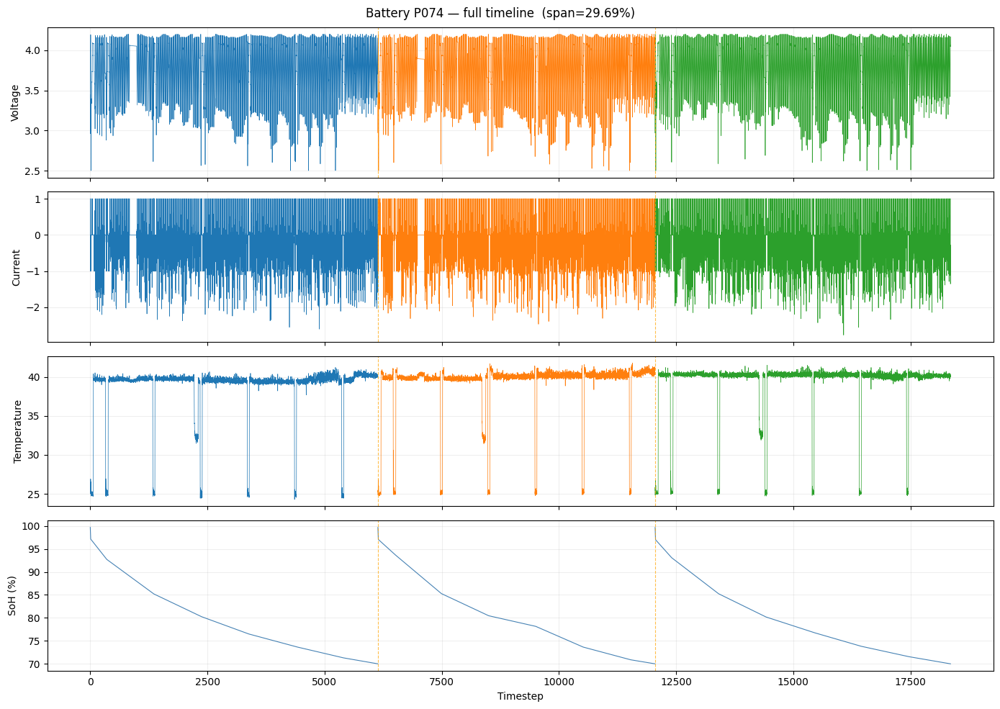

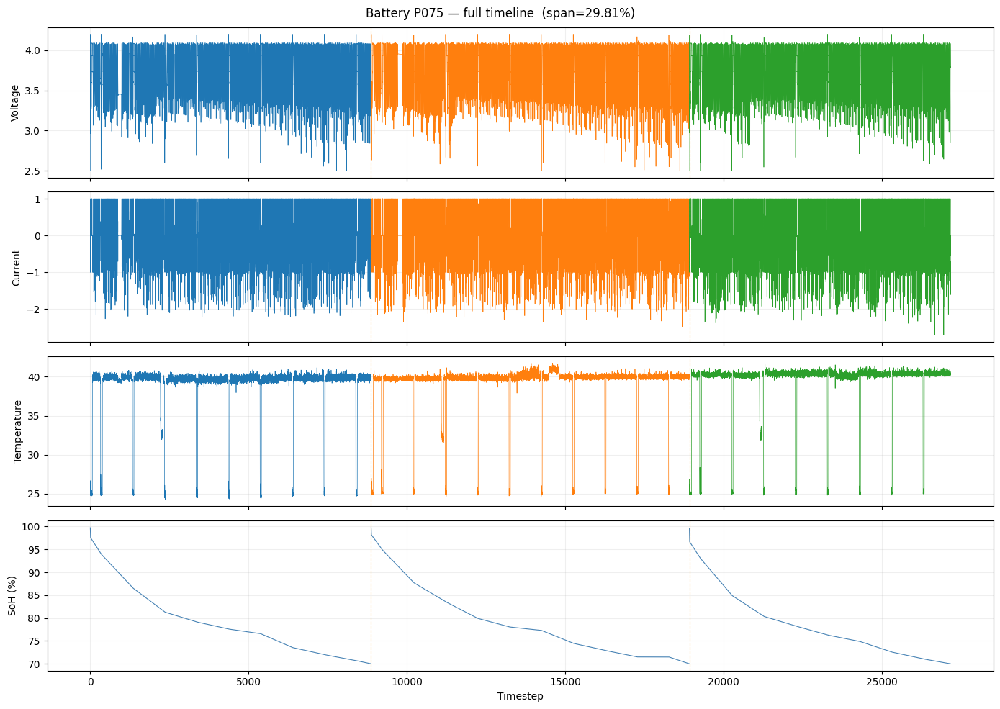

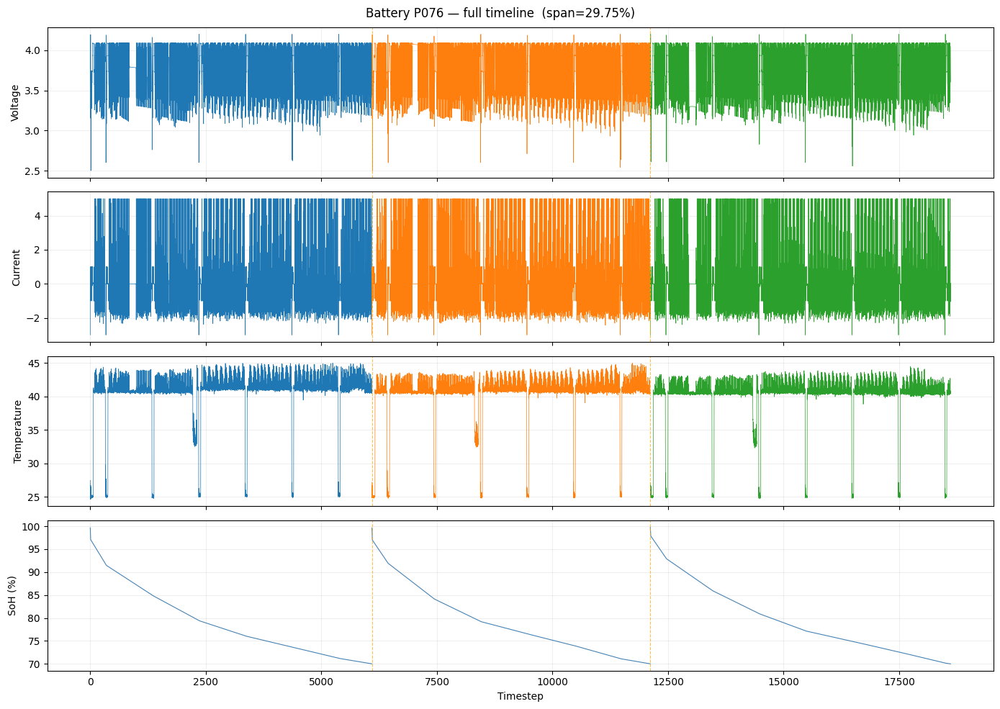

In [ ]:
informative = [r for r in results if r["battery_span"] >= MIN_SPAN_PCT]
print(f"Informative batteries (span >= {MIN_SPAN_PCT}%): {len(informative)}")
for r in informative:
    print(
        f"  {r['battery']}  span={r['battery_span']:.2f}%  "
        f"SoH=[{r['soh_min']:.2f},{r['soh_max']:.2f}]  files={r['n_files']}"
    )

if not informative:
    print("\n No batteries pass the threshold — see Section 6.")
else:
    for r in informative:
        bid = r["battery"]
        files = sorted(battery_files[bid])
        fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
        offset = 0
        boundaries = [0]
        for f in files:
            x = np.load(os.path.join(PROC_DIR, f))
            t = np.arange(offset, offset + len(x))
            axes[0].plot(t, x[:, 1], lw=0.5)
            axes[1].plot(t, x[:, CURRENT_COL], lw=0.5)
            axes[2].plot(t, x[:, 3], lw=0.5)
            axes[3].plot(t, x[:, SOH_COL], lw=0.8, color="steelblue")
            offset += len(x)
            boundaries.append(offset)
        for b in boundaries[1:-1]:
            for ax in axes:
                ax.axvline(b, color="orange", ls="--", lw=0.8, alpha=0.7)
        for ax, lbl in zip(axes, ["Voltage", "Current", "Temperature", "SoH (%)"]):
            ax.set_ylabel(lbl)
            ax.grid(alpha=0.2)
        axes[-1].set_xlabel("Timestep")
        fig.suptitle(
            f"Battery {bid} — full timeline  (span={r['battery_span']:.2f}%)",
            fontsize=12,
        )
        plt.tight_layout()
        plt.show()
